# Data Visualization and AI for Hospiatl Performance Analytics and Forecasting

##1 Business Understanding

## 1.5 Key Performance Indicators

The analysis focuses on the following hospital indicators:

| Indicator | Meaning | Why it matters |
|---|---|---|
| OPD Attendance | Number of outpatient visits | Helps understand outpatient demand |
| IPD Admissions | Number of inpatient admissions | Supports inpatient capacity planning |
| Discharge | Number of patients discharged | Helps understand patient flow |
| Emergency Visits | Number of emergency visits | Helps anticipate emergency service demand |
| Bed Availability | Number of available beds | Indicates available inpatient capacity |
| BOR | Bed Occupancy Rate | Measures how intensively beds are being used |
| ALOS | Average Length of Stay | Indicates average duration of inpatient care |

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)
from matplotlib.gridspec import GridSpec
import matplotlib.dates as mdates
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
df = pd.read_excel(
    '/content/drive/MyDrive/#Note Book/AURH_EMR_data_for_Analysis.xlsx'
)

df.head()

,S.N,Months,OPD Attendance,IPD Admissions,Discharge,Emergency Visits,Bed Availabilty,BOR,ALOS
0,1,Hamle 2016,8582,591,537,625,184,0.73,4.70
1,2,Nehase 2016,6759,551,498,616,184,0.70,5.50
2,3,Meskerem 2016,7099,632,570,613,184,0.71,4.90
3,4,Tikemt 2016,7048,727,661,593,184,0.72,4.40
4,5,Hidar 2016,7278,667,593,645,178,0.82,5.30


# 📊 Phase 2 — Data Understanding

## 2.1 Data Source


The dataset contains 36 monthly observations and 9 original variables.

In [ ]:
# Summary statistics
display(df.describe())

,S.N,OPD Attendance,IPD Admissions,Discharge,Emergency Visits,Bed Availabilty,BOR,ALOS
count,36.00,36.00,36.00,36.00,36.00,36.00,36.00,36.00
mean,18.50,11455.97,624.19,563.03,673.17,179.17,0.78,4.82
std,10.54,2957.59,58.32,54.44,178.90,3.16,0.05,0.71
min,1.00,6759.00,477.00,426.00,448.00,174.00,0.68,3.20
25%,9.75,8865.50,592.50,539.25,551.50,178.00,0.75,4.55
50%,18.50,11101.00,612.00,560.50,613.00,178.00,0.80,4.90
75%,27.25,13153.75,664.00,593.25,805.00,180.00,0.82,5.22
max,36.00,19016.00,739.00,670.00,1107.00,184.00,0.85,7.00


In [ ]:
df.columns = df.columns.str.strip()

df = df.rename(columns={
    "Bed Availabilty": "Bed Availability"
})

In [ ]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (36, 9)

Missing values:
S.N                 0
Months              0
OPD Attendance      0
IPD Admissions      0
Discharge           0
Emergency Visits    0
Bed Availability    0
BOR                 0
ALOS                0
dtype: int64

Duplicate rows: 0

Data types:
S.N                   int64
Months               object
OPD Attendance        int64
IPD Admissions        int64
Discharge             int64
Emergency Visits      int64
Bed Availability      int64
BOR                 float64
ALOS                float64
dtype: object


In [ ]:
print(df['Months'].unique())

['Hamle 2016' 'Nehase 2016' 'Meskerem  2016' 'Tikemt 2016' 'Hidar  2016'
 'Tahesas  2016' 'Tir  2016' 'Yekatit 2016' 'Megabit 2016' 'Miazia 2016'
 'Ginbot 2016' 'Sene 2016' 'Hamle 2017' 'Nehase 2017' 'Meskerem 2017'
 'Tikemt 2017' 'Hidar 2017' 'Tahesas 2017' 'Tir 2017' 'Yekatit 2017'
 'Megabit 2017' 'Miazia 2017' 'Ginbot 2017' 'Sene 2017' 'Hamle 2018'
 'Nehase 2018' 'Meskerem 2018' 'Tikemt 2018' 'Hidar 2018' 'Tahesas 2018'
 'Tir 2018' 'Yekatit 2018' 'Megabit 2018' 'Miazia 2018' 'Ginbot 2018'
 'Sene 2018']


In [ ]:
# Remove S.N column
df.drop(columns="S.N", inplace=True)

# Create monthly Gregorian dates
df["Date"] = pd.date_range(
    start="2023-07-01",
    periods=len(df),
    freq="MS"
)
df.set_index("Date", inplace=True)
# Create Gregorian month name from the Date index
df["GC_Month"] = df.index.strftime("%B")
df.head()

,Months,OPD Attendance,IPD Admissions,Discharge,Emergency Visits,Bed Availability,BOR,ALOS,GC_Month
Date,,,,,,,,,
2023-07-01,Hamle 2016,8582,591,537,625,184,0.73,4.70,July
2023-08-01,Nehase 2016,6759,551,498,616,184,0.70,5.50,August
2023-09-01,Meskerem 2016,7099,632,570,613,184,0.71,4.90,September
2023-10-01,Tikemt 2016,7048,727,661,593,184,0.72,4.40,October
2023-11-01,Hidar 2016,7278,667,593,645,178,0.82,5.30,November


###Exploratory Data Analysis (EDA)

###Step 1:  Time-Series Trend Analysis



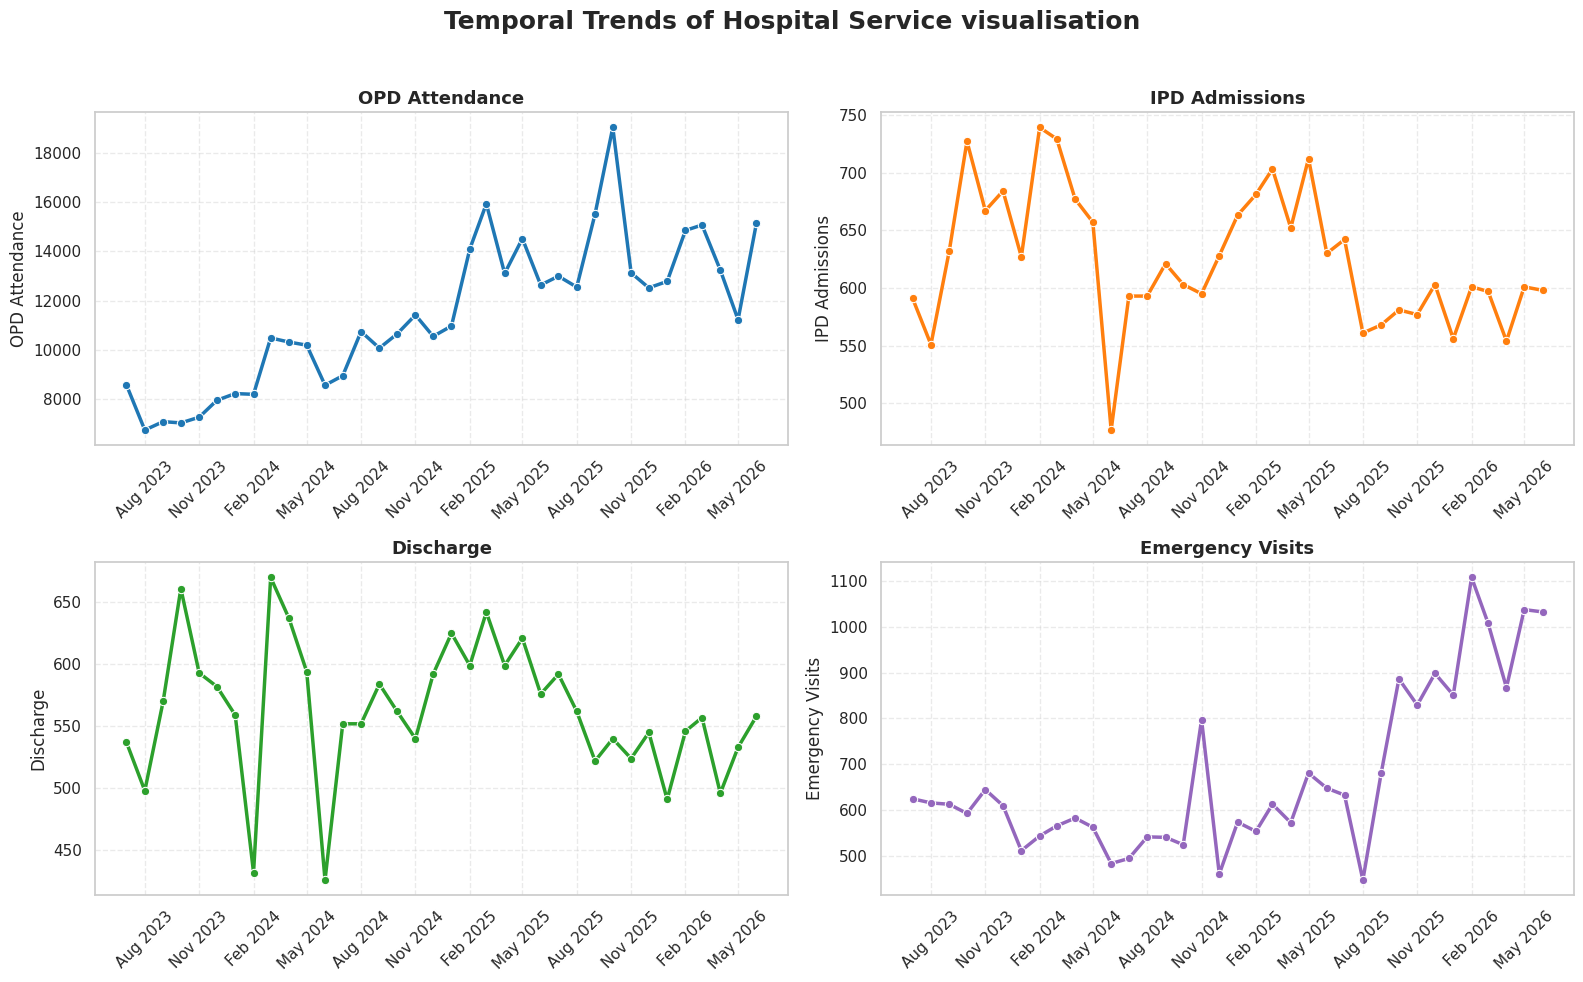

In [ ]:
# Figure 2. Temporal trends in hospital service utilization indicators.

sns.set_theme(style="whitegrid")

activity_variables = [
    'OPD Attendance',
    'IPD Admissions',
    'Discharge',
    'Emergency Visits'
]

colors = [
    '#1f77b4',
    '#ff7f0e',
    '#2ca02c',
    '#9467bd'
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, (ax, var) in enumerate(zip(axes, activity_variables)):

    sns.lineplot(
        data=df,
        x='Date',
        y=var,
        marker='o',
        markersize=6,
        linewidth=2.5,
        color=colors[i],
        ax=ax
    )

    ax.set_title(var, fontsize=13, fontweight='bold')
    ax.set_xlabel("")
    ax.set_ylabel(var)

    # Show labels every 3 months
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

    # Rotate labels
    ax.tick_params(axis='x', rotation=45)

    # Grid
    ax.grid(True, linestyle='--', alpha=0.4)

plt.suptitle(
    "Temporal Trends of Hospital Service visualisation",
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

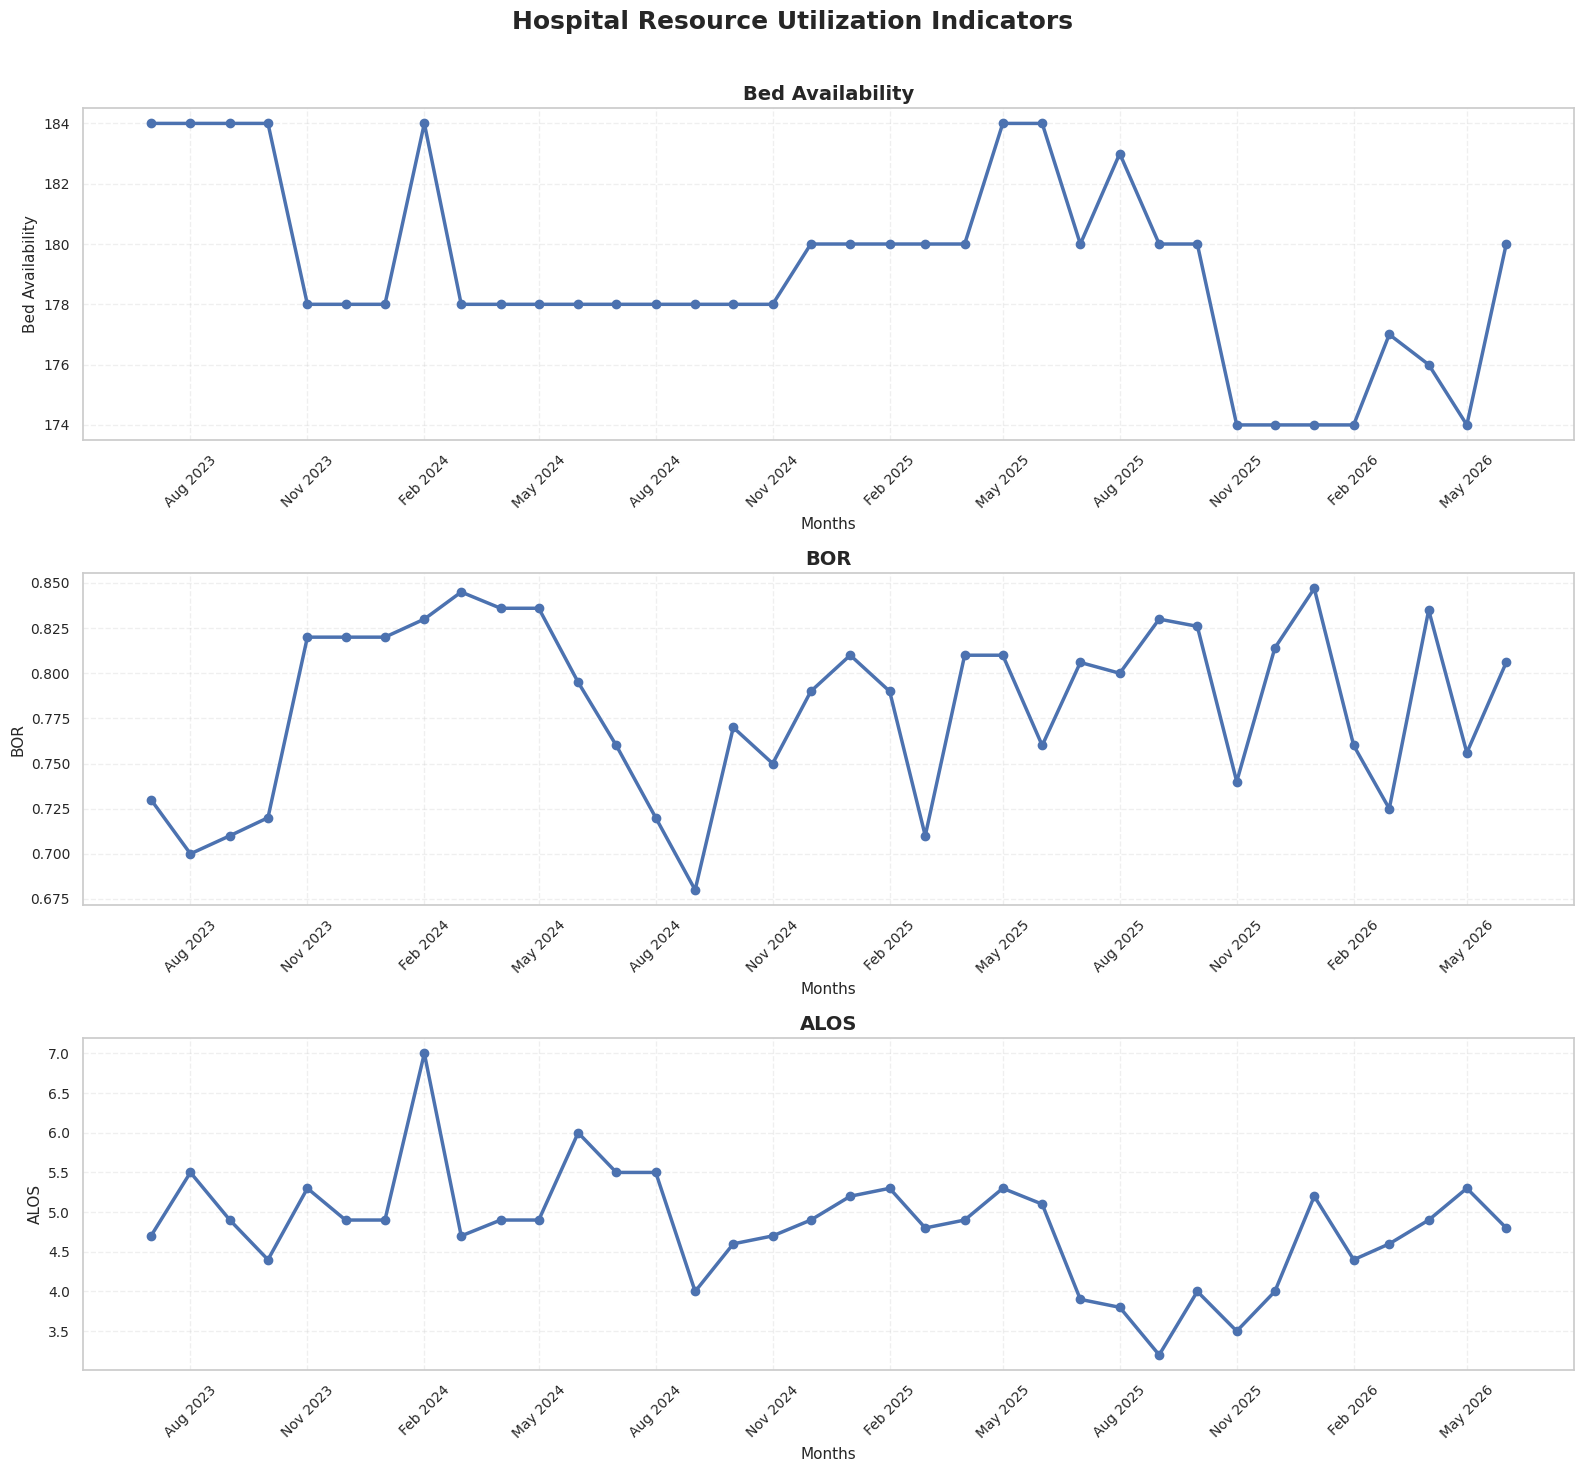

In [ ]:
# Figure 3. Temporal trends in hospital capacity and utilization indicators.
resource_cols = [
    "Bed Availability",
    "BOR",
    "ALOS"
]

fig, axes = plt.subplots(3, 1, figsize=(16, 15))

for ax, col in zip(axes, resource_cols):

    ax.plot(
        df.index,
        df[col],
        marker="o",
        markersize=6,
        linewidth=2.5
    )

    ax.set_title(col, fontsize=14, fontweight="bold")
    ax.set_xlabel("Months", fontsize=11)
    ax.set_ylabel(col, fontsize=11)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

    ax.tick_params(axis="x", rotation=45, labelsize=10)
    ax.tick_params(axis="y", labelsize=10)

    ax.grid(True, linestyle="--", alpha=0.3)

plt.suptitle(
    "Hospital Resource Utilization Indicators",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

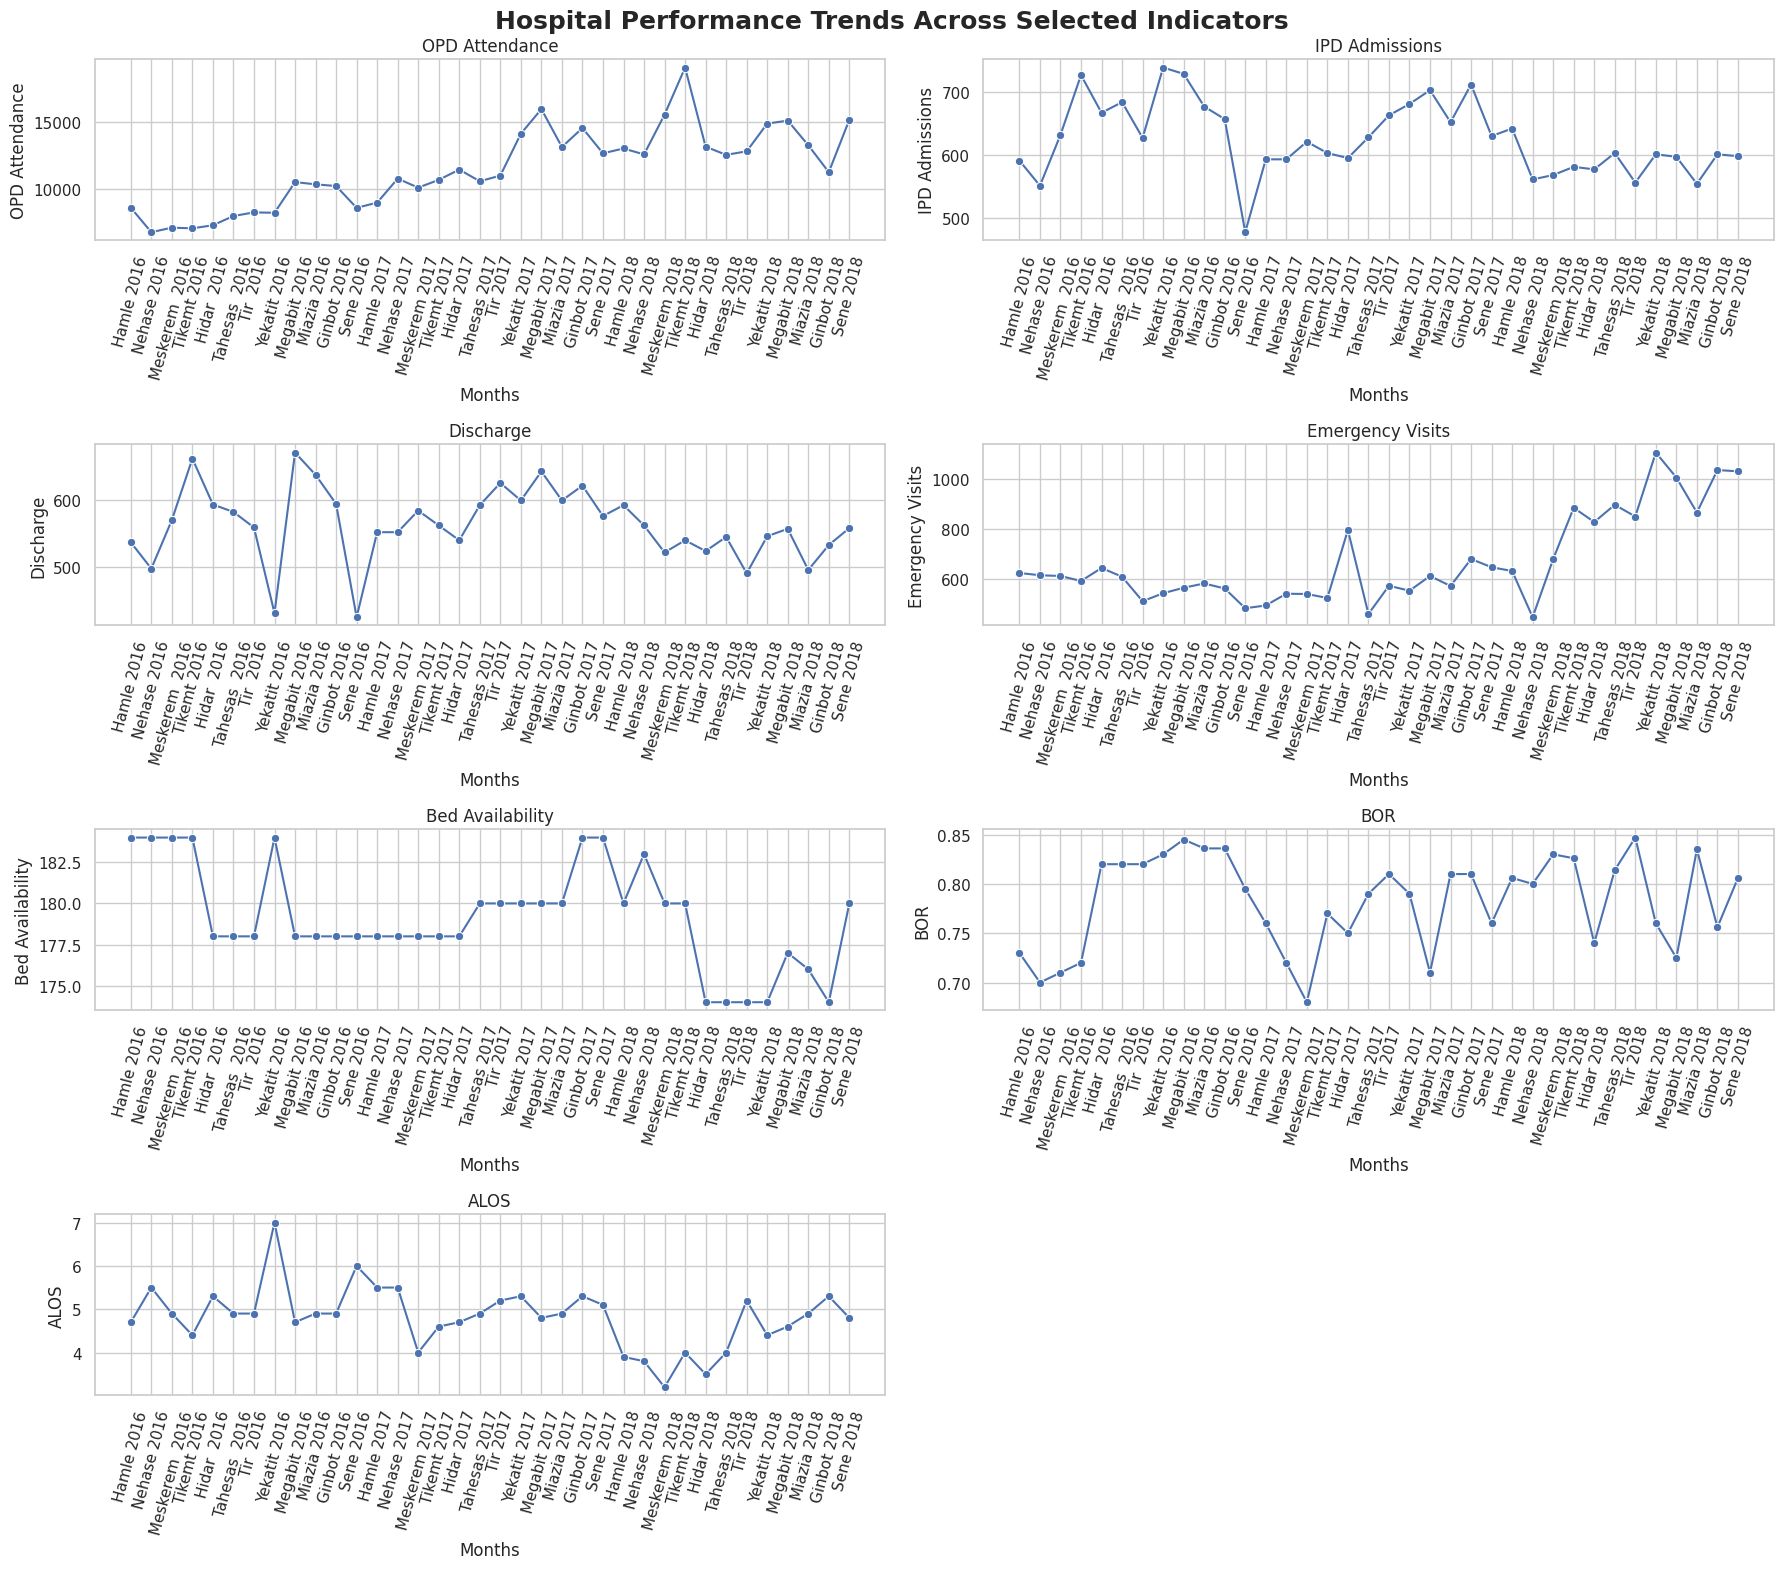

In [ ]:
#Fig for appendex with ethiopian month
fig, axes = plt.subplots(4, 2, figsize=(18, 16))

variables = [
    'OPD Attendance',
    'IPD Admissions',
    'Discharge',
    'Emergency Visits',
    'Bed Availability',
    'BOR',
    'ALOS'
]

for ax, var in zip(axes.flatten(), variables):
    sns.lineplot(
        data=df,
        x='Months',
        y=var,
        marker='o',
        ax=ax
    )

    ax.set_title(var)
    ax.tick_params(axis='x', rotation=75)

# Remove the unused 8th subplot
fig.delaxes(axes.flatten()[-1])

plt.suptitle(
    "Hospital Performance Trends Across Selected Indicators",
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

###Step 2: Correlation Analysis
Hospital indicators often move together

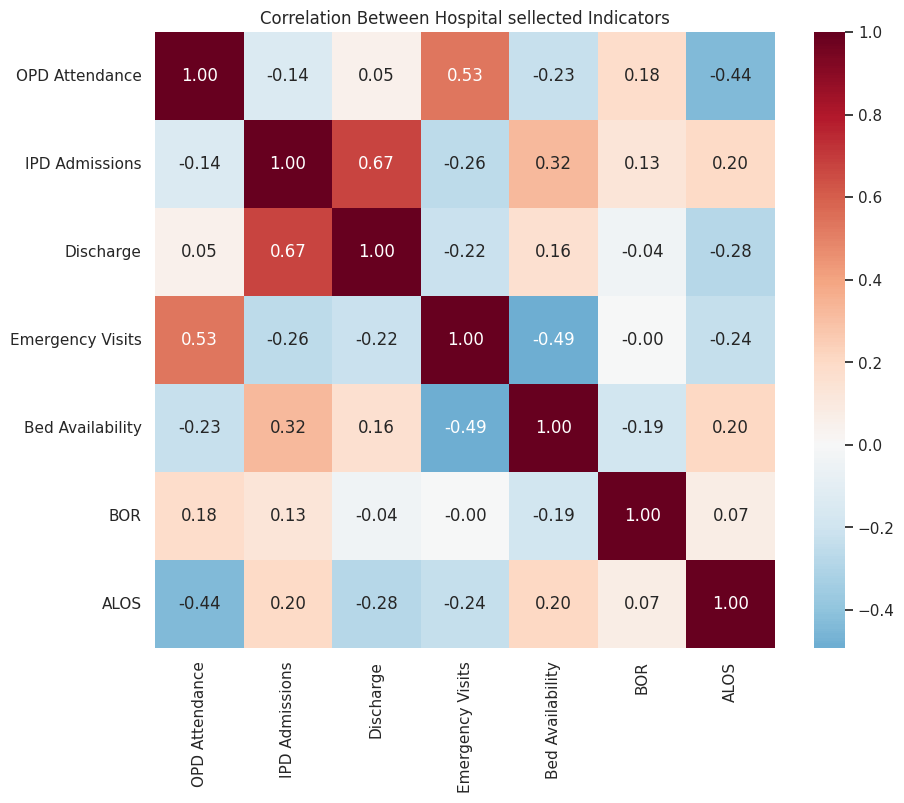

In [ ]:
#Figure 4. Correlation matrix of hospital performance indicators.
#To Interpret:

# Strong positive correlations
# Strong negative correlations
# Weak relationships

plt.figure(figsize=(10,8))

corr = df[variables].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='RdBu_r',
    center=0,
    fmt=".2f"
)

plt.title("Correlation Between Hospital sellected Indicators")
plt.show()

## 3 Data Preparation

In [ ]:
print(df['Months'].unique())

['Hamle 2016' 'Nehase 2016' 'Meskerem  2016' 'Tikemt 2016' 'Hidar  2016'
 'Tahesas  2016' 'Tir  2016' 'Yekatit 2016' 'Megabit 2016' 'Miazia 2016'
 'Ginbot 2016' 'Sene 2016' 'Hamle 2017' 'Nehase 2017' 'Meskerem 2017'
 'Tikemt 2017' 'Hidar 2017' 'Tahesas 2017' 'Tir 2017' 'Yekatit 2017'
 'Megabit 2017' 'Miazia 2017' 'Ginbot 2017' 'Sene 2017' 'Hamle 2018'
 'Nehase 2018' 'Meskerem 2018' 'Tikemt 2018' 'Hidar 2018' 'Tahesas 2018'
 'Tir 2018' 'Yekatit 2018' 'Megabit 2018' 'Miazia 2018' 'Ginbot 2018'
 'Sene 2018']


In [ ]:
df[['Month', 'Year']] = df['Months'].str.extract(r'(.+?)\s+(\d{4})')

df['Year'] = df['Year'].astype(int)

### Performance Analysis for each sellected Indicators by year

In [ ]:
sns.set_theme(style="whitegrid")

colors = {
    2016: "#6C7A89",
    2017: "#1F77B4",
    2018: "#2CA02C"
}

def plot_year_comparison(ax, df, indicator, title, ylabel,
                         fill=False, target_lines=None):

    for year in sorted(df["Year"].unique()):
        d = df[df["Year"] == year]

        ax.plot(
            d["GC_Month"],
            d[indicator],
            marker="o",
            linewidth=2.5,
            label=f"EFY {year}",
            color=colors[year]
        )

        if fill:
            ax.fill_between(
                d["GC_Month"],
                d[indicator],
                alpha=0.15,
                color=colors[year]
            )

    if target_lines:
        for value, color, label in target_lines:
            ax.axhline(value,
                       color=color,
                       linestyle="--",
                       linewidth=1.5,
                       label=label)

    ax.set_title(title,
                 fontsize=13,
                 fontweight="bold")

    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.30)
    ax.legend(fontsize=8)

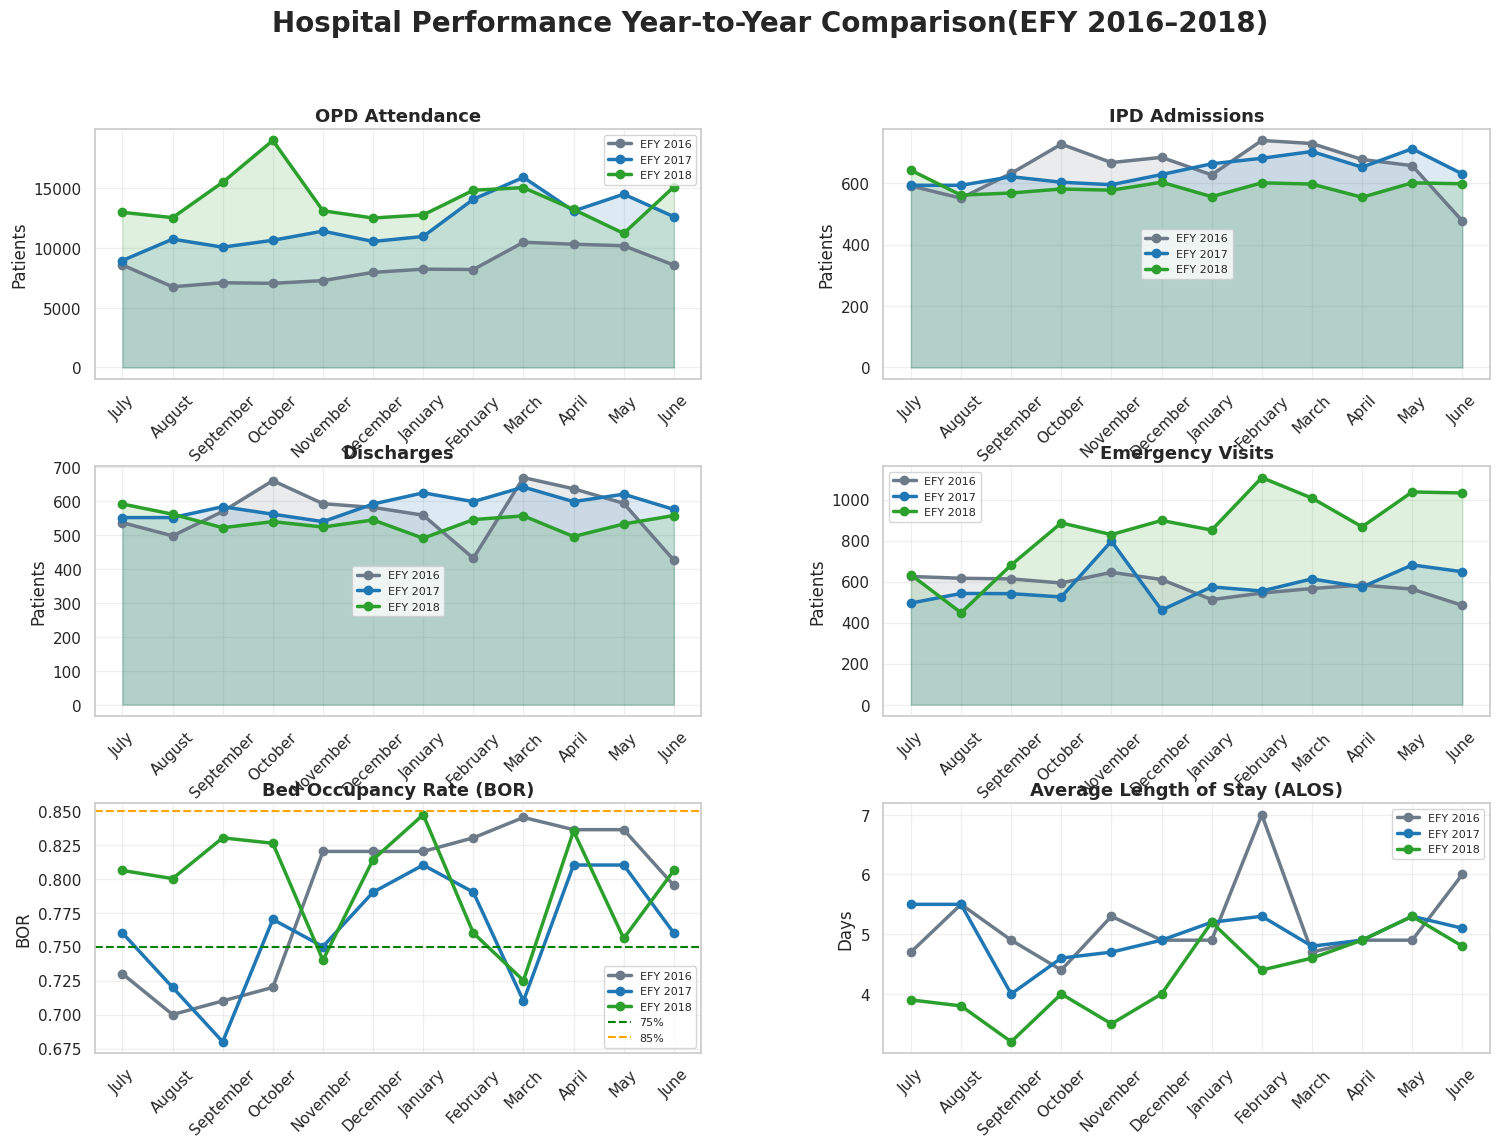

In [ ]:
# figure
fig = plt.figure(figsize=(18, 12))

gs = GridSpec(
    3,
    2,
    figure=fig,
    wspace=0.30,
    hspace=0.35
)

axes = [fig.add_subplot(gs[i, j]) for i in range(3) for j in range(2)]

indicators = [
    ("OPD Attendance", "OPD Attendance", "Patients"),
    ("IPD Admissions", "IPD Admissions", "Patients"),
    ("Discharge", "Discharges", "Patients"),
    ("Emergency Visits", "Emergency Visits", "Patients"),
    ("BOR", "Bed Occupancy Rate (BOR)", "BOR")
]

# First five charts
for ax, (col, title, ylabel) in zip(axes[:5], indicators):

    if col == "BOR":
        plot_year_comparison(
            ax,
            df,
            col,
            title,
            ylabel,
            target_lines=[
                (0.75, "green", "75%"),
                (0.85, "orange", "85%")
            ]
        )

    else:
        plot_year_comparison(
            ax,
            df,
            col,
            title,
            ylabel,
            fill=True
        )

# Sixth chart (ALOS)
plot_year_comparison(
    axes[5],
    df,
    "ALOS",
    "Average Length of Stay (ALOS)",
    "Days"
)

plt.suptitle(
    "Hospital Performance Year-to-Year Comparison(EFY 2016–2018)",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout(rect=[0,0,1,0.96])

plt.show()

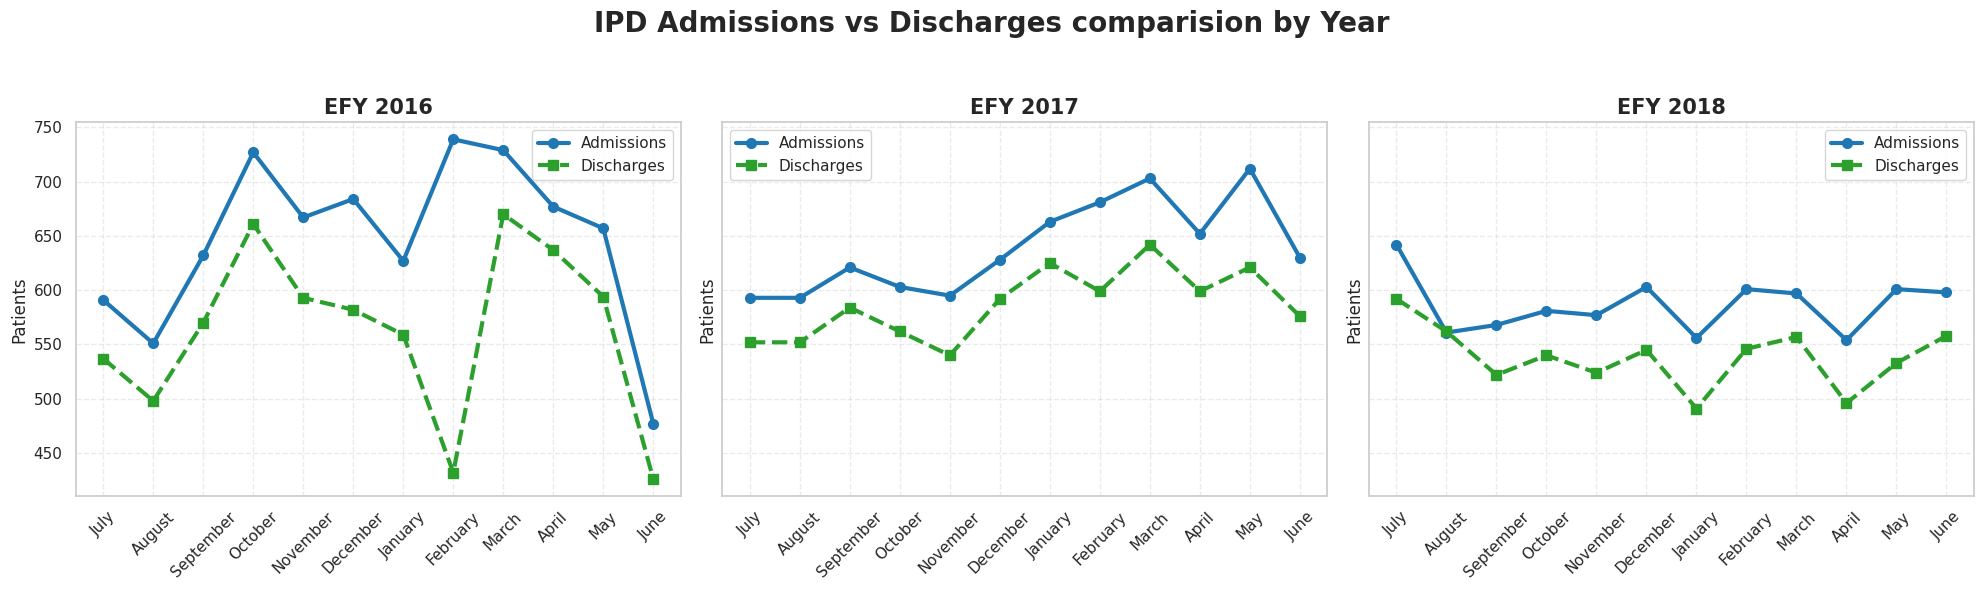

In [ ]:
#Appendex...
sns.set_theme(style="whitegrid")

colors = {
    "Admission": "#1F77B4",   # Blue
    "Discharge": "#2CA02C"    # Green
}

years = sorted(df["Year"].unique())

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)

for ax, year in zip(axes, years):

    d = df[df["Year"] == year]

    ax.plot(
        d["GC_Month"],
        d["IPD Admissions"],
        marker="o",
        linewidth=3,
        markersize=7,
        color=colors["Admission"],
        label="Admissions"
    )
    ax.plot(
        d["GC_Month"],
        d["Discharge"],
        marker="s",
        linewidth=3,
        markersize=7,
        linestyle="--",
        color=colors["Discharge"],
        label="Discharges"
    )

    ax.set_title(
        f"EFY {year}",
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel("")
    ax.set_ylabel("Patients")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend()
plt.suptitle(
    "IPD Admissions vs Discharges comparision by Year",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

###EDA Summary

Key findings

Implications for forecasting

## 4 Modeling

In [ ]:
df.index = pd.to_datetime(df.index)
df = df.sort_index()

In [ ]:
print(df.index.min())
print(df.index.max())
print(df.shape)

2023-07-01 00:00:00
2026-06-01 00:00:00
(36, 11)


In [ ]:
df.keys()

Index(['Months', 'OPD Attendance', 'IPD Admissions', 'Discharge',
       'Emergency Visits', 'Bed Availability', 'BOR', 'ALOS', 'GC_Month',
       'Month', 'Year'],
      dtype='object')

https://forecastegy.com/posts/multiple-time-series-forecasting-with-prophet-in-python/


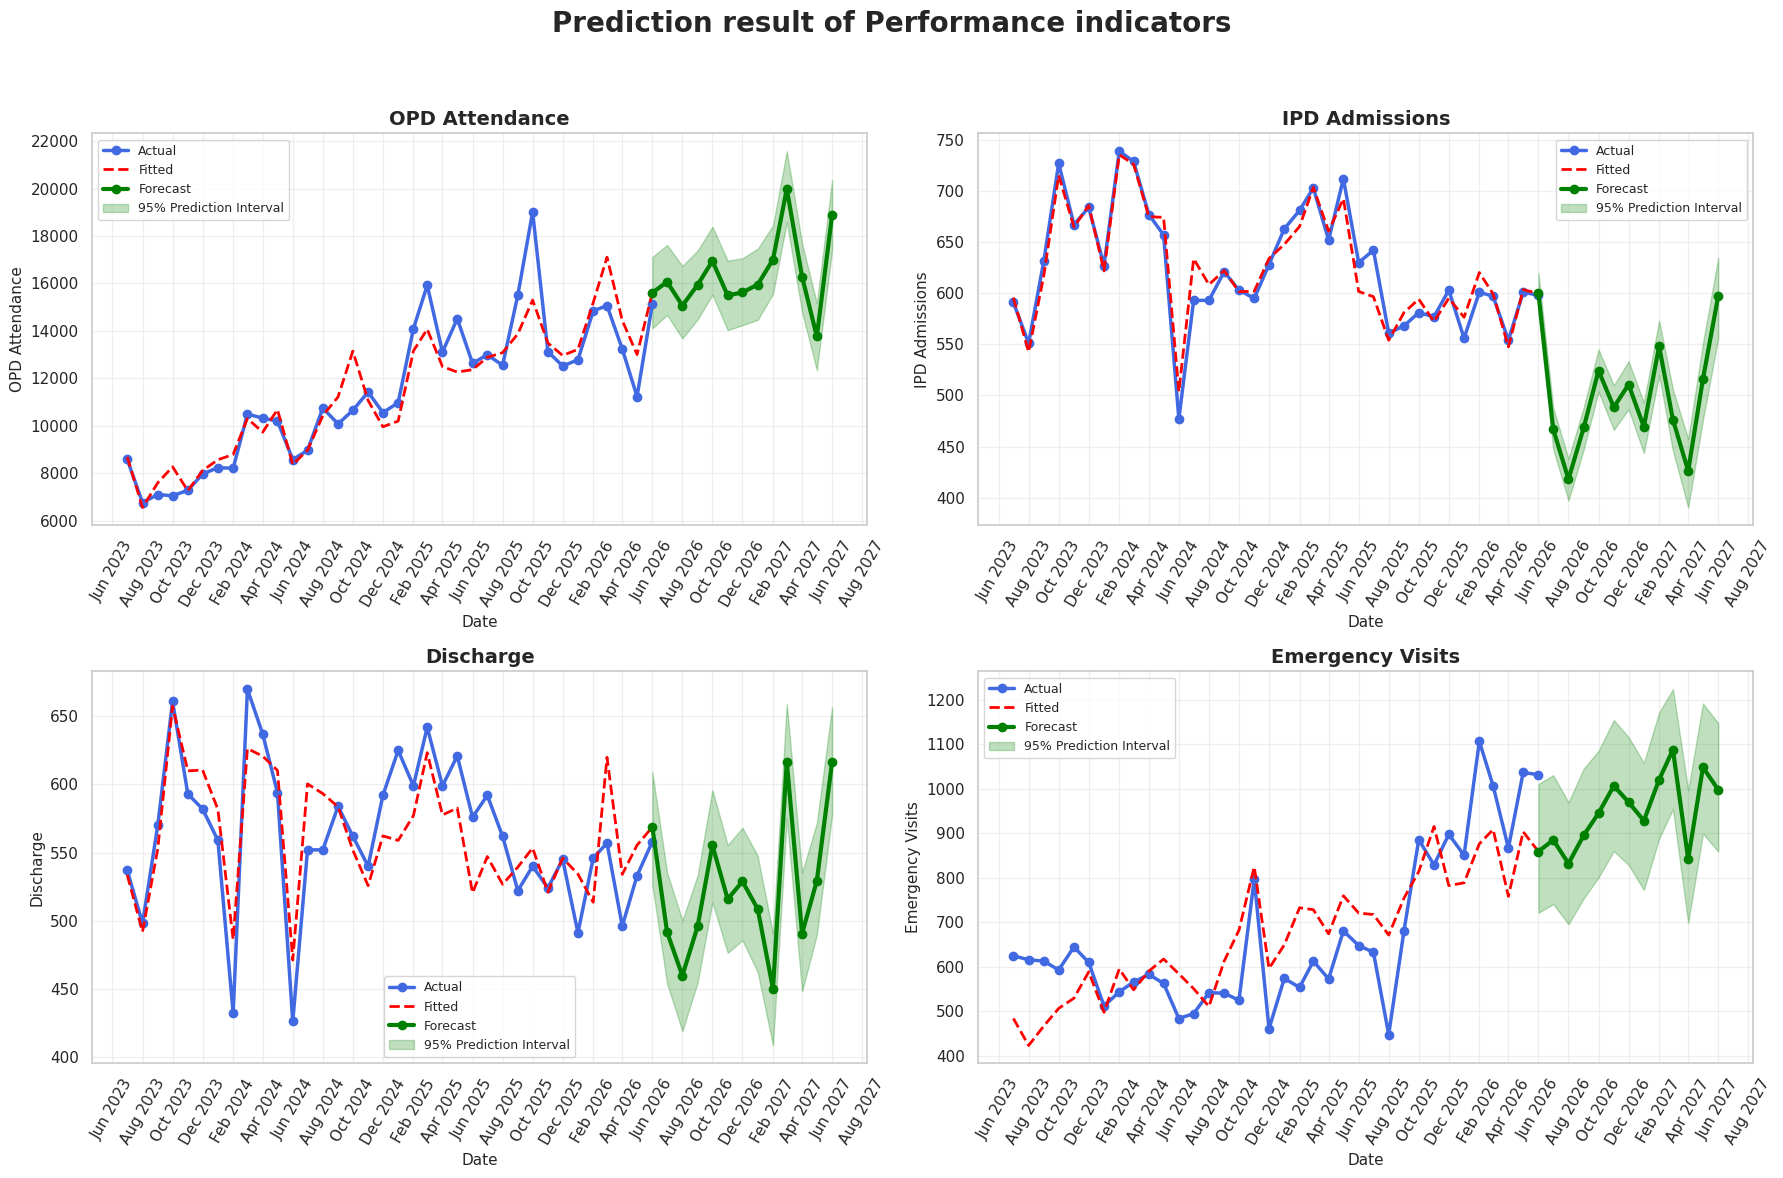

In [ ]:
targets = [
    "OPD Attendance",
    "IPD Admissions",
    "Discharge",
    "Emergency Visits"
]
fitted_values = {}
# Create 2 × 2 figure
fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 12)
)

axes = axes.flatten()

for ax, target in zip(axes, targets):

    # Prepare data for Prophet
    data = df[[target]].reset_index()
    data.columns = ["ds", "y"]

    # Create and fit Prophet model
    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        n_changepoints=12,
        changepoint_prior_scale=0.05
    )

    model.fit(data)

    # Forecast next 12 months
    future = model.make_future_dataframe(
        periods=12,
        freq="MS"
    )

    forecast = model.predict(future)
    fitted_values[target] = forecast["yhat"].iloc[:len(data)].values

    # -----------------------------
    # Historical observations
    # -----------------------------
    ax.plot(
        data["ds"],
        data["y"],
        color="royalblue",
        linewidth=2.5,
        marker="o",
        label="Actual"
    )

    # -----------------------------
    # Fitted values
    # -----------------------------
    ax.plot(
        forecast["ds"][:len(data)],
        forecast["yhat"][:len(data)],
        color="red",
        linestyle="--",
        linewidth=2,
        label="Fitted"
    )

    # -----------------------------
    # Future forecast
    # Include last historical point
    # to connect actual → forecast
    # -----------------------------
    future_forecast = forecast.iloc[len(data)-1:]

    ax.plot(
        future_forecast["ds"],
        future_forecast["yhat"],
        color="green",
        linewidth=3,
        marker="o",
        label="Forecast"
    )

    # -----------------------------
    # 95% prediction interval
    # -----------------------------
    ax.fill_between(
        future_forecast["ds"],
        future_forecast["yhat_lower"],
        future_forecast["yhat_upper"],
        color="green",
        alpha=0.25,
        label="95% Prediction Interval"
    )

    # -----------------------------
    # Titles and labels
    # -----------------------------
    ax.set_title(
        target,
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Date", fontsize=11)
    ax.set_ylabel(target, fontsize=11)

    ax.grid(alpha=0.3)

    # X-axis: monthly
    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=2)
    )

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%b %Y")
    )

    ax.tick_params(
        axis="x",
        rotation=60
    )

    ax.legend(fontsize=9)


# Overall title
plt.suptitle(
    "Prediction result of Performance indicators",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()

## 5 Model Evaluation

In [ ]:
results = []

for target in targets:

    actual = df[target].values
    predicted = fitted_values[target]

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    smape = np.mean(
        2 * np.abs(actual - predicted) /
        (np.abs(actual) + np.abs(predicted))
    ) * 100

    mape = mean_absolute_percentage_error(actual, predicted) * 100

    r2 = r2_score(actual, predicted)

    results.append({
        "Indicator": target,
        "sMAPE (%)": smape,
        "MAPE": mape,
        "R²" :r2
    })

evaluation_df = pd.DataFrame(results).round(2)

evaluation_df

,Indicator,sMAPE (%),MAPE,R²
0,OPD Attendance,6.60,6.65,0.84
1,IPD Admissions,1.84,1.85,0.93
2,Discharge,4.83,4.85,0.64
3,Emergency Visits,14.81,15.11,0.59


In [ ]:
evaluation_df.style\
.background_gradient(cmap="Blues", subset=["sMAPE (%)", "MAPE"])\
.background_gradient(cmap="Greens", subset=["R²"])\
.format({
    "sMAPE (%)":"{:.2f}",
    "MAPE ":"{:.2f}",
    "R²":"{:.3f}"
})

,Indicator,sMAPE (%),MAPE,R²
0,OPD Attendance,6.60,6.650000,0.840
1,IPD Admissions,1.84,1.850000,0.930
2,Discharge,4.83,4.850000,0.640
3,Emergency Visits,14.81,15.110000,0.590


In [ ]:

# Extract Ethiopian Fiscal Year (EFY) from the Months column
df["EFY"] = df["Months"].str.extract(r"(\d{4})").astype(int)
count_columns = [
    "OPD Attendance",
    "IPD Admissions",
    "Discharge",
    "Emergency Visits"
]

annual_totals = df.groupby("EFY")[count_columns].sum()
annual_pct_change = annual_totals.pct_change() * 100
print("Annual totals:")
print(annual_totals.round(2))
print("\nYear-by-year percentage change (%):")
print(annual_pct_change.round(2))

average_columns = ["Bed Availability", "BOR", "ALOS"]
annual_averages = df.groupby("EFY")[average_columns].mean()

print("\nAnnual averages:")
print(annual_averages.round(2))


Annual totals:
      OPD Attendance  IPD Admissions  Discharge  Emergency Visits
EFY                                                              
2016          100759            7758       6759              6954
2017          143657            7674       7044              7004
2018          167999            7039       6466             10276

Year-by-year percentage change (%):
      OPD Attendance  IPD Admissions  Discharge  Emergency Visits
EFY                                                              
2016             NaN             NaN        NaN               NaN
2017           42.57           -1.08       4.22              0.72
2018           16.94           -8.27      -8.21             46.72

Annual averages:
      Bed Availability  BOR  ALOS
EFY                              
2016            180.50 0.79  5.18
2017            179.83 0.76  4.98
2018            177.17 0.80  4.30


Reference

https://www.google.com/url?q=https%3A%2F%2Fforecastegy.com%2Fposts%2Fmultiple-time-series-forecasting-with-prophet-in-python%2F

